# 26. Querétaro 물리 근거 — 조건이 어느 방향으로 벗어나면 어떤 불량이 생기는가 (작업 1~3)
- 데이터: Domínguez 외 2025, Mendeley Data V3, `Data_RSW.csv`(타점당 약 100ms 간격 전류·힘 시계열 + 실측 품질). README 파일은 폴더에 없다.
- 필터: `Comments == "DOE"` 33타점(35·95psi 극단 조건, 판 두께 0.92mm)을 빼고 생산형 462타점만 쓴다.
- 모델을 학습하지 않는다. 절대값을 KAMP와 비교하지 않는다(설비·단위가 다름). 방향과 상대 크기만 본다.
- 재현 확인: 날림 60psi 24/332 vs 80psi 2/130 (p=0.014), 통전시간–너깃 Spearman ρ=+0.38.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from scipy import stats
import br
from br import plot as P, stat as T
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
QPATH = br.ROOT.parent.parent / "학습용 데이터" / "02_Queretaro_RSW" / "data" / "Queretaro_RSW_v3" / "Data_RSW.csv"
raw = pd.read_csv(QPATH, encoding="utf-8-sig")
raw.columns = ["id", "psi", "ms", "ang", "F", "I", "tA", "tB", "mat", "pull", "nug", "cat", "com"]
print("원자료:", raw.shape, "타점", raw.id.nunique(), "| 열:", list(raw.columns))

원자료: (4186, 13) 타점 495 | 열: ['id', 'psi', 'ms', 'ang', 'F', 'I', 'tA', 'tB', 'mat', 'pull', 'nug', 'cat', 'com']


## 0. 타점 요약표와 재현 확인
- 전류: 첫 샘플(k=0)은 상승 구간이라 평균이 낮다(전체 평균 약 1,950A vs 이후 2,700~3,700A). 본 구간 = k≥1.
- 입열 대리값 Q = (본 구간 전류의 제곱평균) × 통전시간 [A²·s]. **전압·저항이 없으므로 Q=I²Rt에서 R을 뺀 대리값이다.**
- I/F = 본 구간 평균 전류 / 측정 힘 중앙값(데이터의 Force 열, 단위 N 표기. 값의 크기가 공압 실린더 힘으로는 작아 상대값으로만 쓴다).
- 너깃 미달 기준: 4√t (t = 두 판 평균 두께, 약 0.63mm → 약 3.17mm). 자동차 업계에서 흔히 쓰는 최소 너깃 지름 기준을 빌린 것이며 이 데이터의 판정 기준은 아니다.

In [2]:
raw["k"] = raw.groupby("id").cumcount()
g = raw.groupby("id")
S = g[["psi", "ms", "ang", "tA", "tB", "pull", "nug", "cat", "com"]].first()
S["n_samp"] = g.size()
body = raw[raw.k >= 1].groupby("id")
S["I_body"] = body.I.mean(); S["I_rms"] = np.sqrt(body.I.apply(lambda v: np.mean(v ** 2)))
S["F_med"] = g.F.median()
S["com"] = S.com.fillna("")
P_ = S[S.com != "DOE"].copy()
P_["expl"] = (P_.cat == "Explode").astype(int)
P_["bad"] = (P_.cat == "Bad").astype(int)
P_["notgood"] = (P_.cat != "Good").astype(int)
P_["t_mean"] = (P_.tA + P_.tB) / 2
P_["nug_min"] = 4 * np.sqrt(P_.t_mean)
P_["undersize"] = (P_.nug < P_.nug_min).astype(int)
P_["Q"] = P_.I_rms ** 2 * P_.ms / 1000
P_["IF"] = P_.I_body / P_.F_med
P_["psi80"] = (P_.psi == 80).astype(int); P_["ang15"] = (P_.ang == 15).astype(int)
P_["cell"] = P_.psi.astype(str) + "psi/" + P_.ang.astype(str) + "°/" + P_.ms.astype(str) + "ms"
P_["exp_n"] = P_.ms // 100 + 1
P_["cur_ok"] = (P_.n_samp >= P_.exp_n - 1) & P_.I_body.notna()
print("생산형 타점:", len(P_), "| 전류 샘플 수가 통전시간에 비해 모자란 타점(전류 분석에서 제외):", int((~P_.cur_ok).sum()),
      P_.loc[~P_.cur_ok, ["cell", "n_samp", "com"]].to_dict("index"))
t = pd.crosstab(P_.psi, P_.expl)
print("\n[재현 1] 날림:", {p: f"{t.loc[p,1]}/{t.loc[p].sum()} ({t.loc[p,1]/t.loc[p].sum():.1%})" for p in t.index},
      f"Fisher 정확검정 p={stats.fisher_exact(t.values)[1]:.4f}")
print(f"[재현 2] 통전시간–너깃 Spearman ρ={stats.spearmanr(P_.ms, P_.nug)[0]:+.3f} (n={len(P_)})")
P_.reset_index().to_csv(br.RES / "queretaro_samples.csv", index=False, encoding="utf-8-sig")

생산형 타점: 462 | 전류 샘플 수가 통전시간에 비해 모자란 타점(전류 분석에서 제외): 5 {39: {'cell': '60psi/0°/1000ms', 'n_samp': 2, 'com': ''}, 183: {'cell': '80psi/0°/600ms', 'n_samp': 5, 'com': ''}, 240: {'cell': '60psi/15°/1000ms', 'n_samp': 9, 'com': ''}, 250: {'cell': '60psi/15°/1000ms', 'n_samp': 1, 'com': 'Communication error'}, 252: {'cell': '60psi/15°/1000ms', 'n_samp': 1, 'com': 'Communication error'}}

[재현 1] 날림: {60: '24/332 (7.2%)', 80: '2/130 (1.5%)'} Fisher 정확검정 p=0.0137
[재현 2] 통전시간–너깃 Spearman ρ=+0.378 (n=462)


## 1. 실험 구조 (작업 1)

In [3]:
print("수준 수: 가압력", sorted(P_.psi.unique()), "| 통전시간", sorted(P_.ms.unique()), "| 전극 각도", sorted(P_.ang.unique()))
print("전류 설정값 열: 없음. 전압 열: 없음. 저항 열: 없음. 측정 시계열은 전류(A)와 힘(Force)뿐이다.\n")
design = pd.crosstab([P_.psi, P_.ang], P_.ms, margins=True, margins_name="합계")
display(design)
cellsum = P_.groupby("cell").agg(타점=("nug", "size"), 날림=("expl", "sum"), Bad=("bad", "sum"),
                                 측정전류평균=("I_body", "mean"), 측정전류SD=("I_body", "std"), 측정힘=("F_med", "mean"),
                                 너깃평균=("nug", "mean"), 인장평균=("pull", "mean")).round(1)
display(cellsum)
cellsum.to_csv(br.RES / "queretaro_design_cells.csv", encoding="utf-8-sig")
ok = P_.cur_ok
kw = stats.kruskal(*[v.values for _, v in P_[ok].groupby("cell").I_body])
within_sd = P_[ok].groupby("cell").I_body.std().mean()
print(f"측정 전류: 전체 평균 {P_[ok].I_body.mean():.0f}A, 변동계수 {P_[ok].I_body.std()/P_[ok].I_body.mean():.1%}, "
      f"조건 칸 평균의 범위 {cellsum.측정전류평균.min():.0f}~{cellsum.측정전류평균.max():.0f}A (Kruskal p={kw.pvalue:.1e}), 칸 안 평균 SD {within_sd:.0f}A")
print("→ 전류는 설계 요인이 아니다. 조건 칸마다 측정 평균이 다르지만 설정값 기록이 없어, 칸 사이 차이는 다른 조건(가압력·시간·각도·세션)과 분리할 수 없다.")
print("  전류 효과는 '같은 조건 칸 안의 자연 변동'으로만 추정한다(관찰 근거).")

수준 수: 가압력 [np.int64(60), np.int64(80)] | 통전시간 [np.int64(400), np.int64(600), np.int64(800), np.int64(1000), np.int64(1200)] | 전극 각도 [np.int64(0), np.int64(15)]
전류 설정값 열: 없음. 전압 열: 없음. 저항 열: 없음. 측정 시계열은 전류(A)와 힘(Force)뿐이다.



ms       400  600  800  1000  1200   합계
psi ang                                
60  0     50    0    0    22    30  102
    15    49   51   50    50    30  230
80  0      0   50   51    29     0  130
합계        99  101  101   101    60  462

,타점,날림,Bad,측정전류평균,측정전류SD,측정힘,너깃평균,인장평균
cell,,,,,,,,
60psi/0°/1000ms,22,0,0,2873.2,292.7,78.4,4.1,3318.3
60psi/0°/1200ms,30,4,1,3608.6,466.7,97.8,3.7,2791.3
60psi/0°/400ms,50,1,2,2906.7,211.5,92.7,3.4,2766.6
60psi/15°/1000ms,50,0,0,3749.1,214.4,68.8,3.7,3124.8
60psi/15°/1200ms,30,0,0,3147.3,197.1,95.6,3.8,3110.0
60psi/15°/400ms,49,5,1,3041.6,363.8,95.5,3.5,2847.3
60psi/15°/600ms,51,9,0,3746.7,202.2,93.0,3.5,2910.8
60psi/15°/800ms,50,5,0,3482.9,296.1,78.5,3.6,3041.3
80psi/0°/1000ms,29,0,0,3180.3,285.4,103.8,3.5,2896.7


측정 전류: 전체 평균 3271A, 변동계수 12.9%, 조건 칸 평균의 범위 2873~3749A (Kruskal p=8.8e-51), 칸 안 평균 SD 268A
→ 전류는 설계 요인이 아니다. 조건 칸마다 측정 평균이 다르지만 설정값 기록이 없어, 칸 사이 차이는 다른 조건(가압력·시간·각도·세션)과 분리할 수 없다.
  전류 효과는 '같은 조건 칸 안의 자연 변동'으로만 추정한다(관찰 근거).


## 2. 조건별 품질 방향 (작업 2)
각 조건에 대해 (a) 단순 비교와 (b) 다른 조건을 통제한 결과를 낸다.
- 연속 결과(너깃 지름, 인장 하중): 회귀 기울기(최소제곱법, HC3 강건 표준오차로 95% 구간).
- 이진 결과(날림, Bad, 비정상=Bad+날림): Firth 로지스틱(희귀 사건에서도 안정적인 로지스틱 회귀)의 오즈비(odds ratio, 사건 확률비의 근사), 가압력은 비율 차이(Newcombe 구간)와 Fisher 정확검정도 함께.
- 통제 모형
  - 통전시간: 가압력×각도 층(4개) 고정효과 + 통전시간(200ms당 선형)
  - 가압력: 각도 + 통전시간(범주) 고정효과 + 가압력. 80psi는 각도 0°·600~1000ms에만 있어서 **가가산 모형(효과가 더해진다는 가정)에 기대어 분리된다.** 두 가압력이 모두 있는 칸은 (1000ms, 0°) 하나뿐이라 그 칸만 따로 비교한다.
  - 전류: 조건 칸(11개) 고정효과 + 측정 전류(100A당) → 같은 칸 안 변동만 사용
  - 각도: 참고용으로 같은 방식(가압력 + 통전시간 범주) 통제

In [4]:
OUTS = [("nug", "너깃 지름(mm)", "c"), ("pull", "인장 하중(N)", "c"), ("undersize", "너깃 미달(<4√t)", "b"), ("expl", "날림", "b"), ("bad", "Bad 판정", "b"), ("notgood", "비정상(Bad+날림)", "b")]

def dummies(df, cols):
    return pd.get_dummies(df[cols].astype(str), drop_first=True).astype(float)

def fit_effect(df, x, scale, ctrl_cols, out, kind):
    """x의 효과(scale 단위당). 연속: 기울기, 이진: 오즈비. ctrl_cols는 범주형 통제 변수."""
    X = pd.concat([pd.Series(1.0, index=df.index, name="const"), (df[x] / scale).rename("x")] + ([dummies(df, ctrl_cols)] if ctrl_cols else []), axis=1)
    y = df[out].values.astype(float)
    if kind == "c":
        b, se = T.ols(X.values, y); e, lo, hi = b[1], b[1] - T.Z * se[1], b[1] + T.Z * se[1]
        p = 2 * stats.norm.sf(abs(b[1] / se[1]))
        return e, lo, hi, p
    if y.sum() == 0: return np.nan, np.nan, np.nan, np.nan
    b, se = T.firth(X.values, y); p = 2 * stats.norm.sf(abs(b[1] / se[1]))
    return np.exp(b[1]), np.exp(b[1] - T.Z * se[1]), np.exp(b[1] + T.Z * se[1]), p

def fmt(e, lo, hi, kind):
    if np.isnan(e): return "추정 불가(사건 0)"
    return f"{e:+.3f} [{lo:+.3f}, {hi:+.3f}]" if kind == "c" else f"OR {e:.2f} [{lo:.2f}, {hi:.2f}]"

def direction(e, lo, hi, kind):
    if np.isnan(e): return "확인 불가"
    null = 0 if kind == "c" else 1
    if lo > null: return "증가 ↑"
    if hi < null: return "감소 ↓"
    return "유의한 방향 없음"

FACTORS = [
    ("통전시간", "ms", 200, "+200ms당", None, ["psi", "ang"], P_.index),
    ("가압력", "psi80", 1, "80 vs 60psi", None, ["ang", "ms"], P_.index),
    ("측정 전류", "I_body", 100, "+100A당", None, ["cell"], P_.index[P_.cur_ok]),
    ("전극 각도(참고)", "ang15", 1, "15° vs 0°", None, ["psi", "ms"], P_.index),
]
rows = []
for fname, x, sc, unit, _, ctrl, idx in FACTORS:
    df = P_.loc[idx]
    for out, oname, kind in OUTS:
        for mode, cc in (("단순", None), ("통제", ctrl)):
            e, lo, hi, p = fit_effect(df, x, sc, cc, out, kind)
            rows.append({"조건": fname, "단위": unit, "결과": oname, "분석": mode, "통제 변수": "—" if not cc else "+".join(cc),
                         "방향": direction(e, lo, hi, kind), "효과 [95% 구간]": fmt(e, lo, hi, kind), "p": p, "n": len(df),
                         "사건 수": int(df[out].sum()) if kind == "b" else np.nan, "_e": e, "_lo": lo, "_hi": hi})
eff = pd.DataFrame(rows)
eff.drop(columns=["_e", "_lo", "_hi"]).to_csv(br.RES / "queretaro_direction_table.csv", index=False, encoding="utf-8-sig")
display(eff.drop(columns=["_e", "_lo", "_hi"]).round({"p": 4}))

,조건,단위,결과,분석,통제 변수,방향,효과 [95% 구간],p,n,사건 수
0,통전시간,+200ms당,너깃 지름(mm),단순,—,증가 ↑,"+0.092 [+0.068, +0.116]",0.0000,462,NaN
1,통전시간,+200ms당,너깃 지름(mm),통제,psi+ang,증가 ↑,"+0.092 [+0.068, +0.117]",0.0000,462,NaN
2,통전시간,+200ms당,인장 하중(N),단순,—,증가 ↑,"+64.710 [+46.393, +83.027]",0.0000,462,NaN
3,통전시간,+200ms당,인장 하중(N),통제,psi+ang,증가 ↑,"+64.862 [+46.978, +82.746]",0.0000,462,NaN
4,통전시간,+200ms당,너깃 미달(<4√t),단순,—,감소 ↓,"OR 0.69 [0.55, 0.88]",0.0022,462,51.0
5,통전시간,+200ms당,너깃 미달(<4√t),통제,psi+ang,감소 ↓,"OR 0.62 [0.47, 0.83]",0.0010,462,51.0
6,통전시간,+200ms당,날림,단순,—,유의한 방향 없음,"OR 0.80 [0.59, 1.09]",0.1558,462,26.0
7,통전시간,+200ms당,날림,통제,psi+ang,유의한 방향 없음,"OR 0.82 [0.62, 1.09]",0.1769,462,26.0
8,통전시간,+200ms당,Bad 판정,단순,—,유의한 방향 없음,"OR 0.64 [0.30, 1.36]",0.2482,462,4.0
9,통전시간,+200ms당,Bad 판정,통제,psi+ang,유의한 방향 없음,"OR 0.78 [0.45, 1.35]",0.3757,462,4.0


### 2-1. 가압력: 비율 차이와 층별 비교
가압력 효과가 각도와 섞여 있는지 본다. 80psi는 모두 0°이므로, 60psi도 0°만 남긴 비교와 두 가압력이 같이 있는 (1000ms, 0°) 칸 비교를 낸다.

In [5]:
def press_compare(df, label):
    a, b_ = df[df.psi == 60], df[df.psi == 80]
    r = {"비교": label, "60psi n": len(a), "80psi n": len(b_)}
    for out, oname in (("expl", "날림"), ("notgood", "비정상")):
        k1, n1, k2, n2 = a[out].sum(), len(a), b_[out].sum(), len(b_)
        d, lo, hi = T.newcombe(k2, n2, k1, n1)
        r[f"{oname} 60psi"] = f"{k1}/{n1} ({k1/n1:.1%})"; r[f"{oname} 80psi"] = f"{k2}/{n2} ({k2/n2:.1%})"
        r[f"{oname} 차이(80−60) [95%]"] = f"{d:+.1%} [{lo:+.1%}, {hi:+.1%}]"
        r[f"{oname} Fisher p"] = round(stats.fisher_exact([[k1, n1 - k1], [k2, n2 - k2]])[1], 4)
    for out, oname in (("nug", "너깃"), ("pull", "인장")):
        dd = b_[out].mean() - a[out].mean(); se = np.sqrt(a[out].var() / len(a) + b_[out].var() / len(b_))
        r[f"{oname} 차이(80−60) [95%]"] = f"{dd:+.2f} [{dd-T.Z*se:+.2f}, {dd+T.Z*se:+.2f}]"
    return r
pc = pd.DataFrame([press_compare(P_, "전체 462"), press_compare(P_[P_.ang == 0], "각도 0°만"),
                   press_compare(P_[(P_.ang == 0) & (P_.ms == 1000)], "1000ms·0° 칸(두 가압력 공존)"),
                   press_compare(P_[P_.ms.isin([600, 800, 1000])], "600~1000ms만(60psi는 각도 혼재)")]).T
display(pc); pc.to_csv(br.RES / "queretaro_pressure_strata.csv", encoding="utf-8-sig")
print("60psi 각도별 날림:", P_[P_.psi == 60].groupby("ang").expl.agg(["sum", "size"]).to_dict("index"))
print("통전시간별 날림:", P_.groupby("ms").expl.agg(["sum", "size"]).to_dict("index"))

,0,1,2,3
비교,전체 462,각도 0°만,1000ms·0° 칸(두 가압력 공존),600~1000ms만(60psi는 각도 혼재)
60psi n,332,102,22,173
80psi n,130,130,29,130
날림 60psi,24/332 (7.2%),5/102 (4.9%),0/22 (0.0%),14/173 (8.1%)
날림 80psi,2/130 (1.5%),2/130 (1.5%),0/29 (0.0%),2/130 (1.5%)
날림 차이(80−60) [95%],"-5.7% [-9.2%, -1.2%]","-3.4% [-9.5%, +1.4%]","+0.0% [-14.9%, +11.7%]","-6.6% [-11.7%, -1.5%]"
날림 Fisher p,0.0137,0.2451,1.0,0.0168
비정상 60psi,28/332 (8.4%),8/102 (7.8%),0/22 (0.0%),14/173 (8.1%)
비정상 80psi,2/130 (1.5%),2/130 (1.5%),0/29 (0.0%),2/130 (1.5%)
비정상 차이(80−60) [95%],"-6.9% [-10.6%, -2.2%]","-6.3% [-13.3%, -0.9%]","+0.0% [-14.9%, +11.7%]","-6.6% [-11.7%, -1.5%]"


60psi 각도별 날림: {0: {'sum': 5, 'size': 102}, 15: {'sum': 19, 'size': 230}}
통전시간별 날림: {400: {'sum': 6, 'size': 99}, 600: {'sum': 10, 'size': 101}, 800: {'sum': 6, 'size': 101}, 1000: {'sum': 0, 'size': 101}, 1200: {'sum': 4, 'size': 60}}


### 2-2. 통전시간: 층별 Spearman 상관

In [6]:
rows = []
for (ps, an), d_ in P_.groupby(["psi", "ang"]):
    if d_.ms.nunique() < 2: continue
    for out, oname in (("nug", "너깃"), ("pull", "인장")):
        r, lo, hi, p = T.spearman_boot(d_.ms, d_[out], B=1000, seed=1)
        rows.append({"층": f"{ps}psi/{an}°", "통전시간 수준": sorted(d_.ms.unique()), "결과": oname, "ρ [95%]": f"{r:+.2f} [{lo:+.2f}, {hi:+.2f}]", "n": len(d_)})
for out, oname in (("nug", "너깃"), ("pull", "인장")):
    r, lo, hi, p = T.spearman_boot(P_.ms, P_[out], B=1000, seed=1)
    rows.append({"층": "전체", "통전시간 수준": sorted(P_.ms.unique()), "결과": oname, "ρ [95%]": f"{r:+.2f} [{lo:+.2f}, {hi:+.2f}]", "n": len(P_)})
st = pd.DataFrame(rows); display(st); st.to_csv(br.RES / "queretaro_time_strata.csv", index=False, encoding="utf-8-sig")
print("통전시간별 너깃 평균:", P_.groupby("ms").nug.mean().round(2).to_dict(), "| 인장 평균:", P_.groupby("ms").pull.mean().round(0).to_dict())

,층,통전시간 수준,결과,ρ [95%],n
0,60psi/0°,"[400, 1000, 1200]",너깃,"+0.51 [+0.33, +0.66]",102
1,60psi/0°,"[400, 1000, 1200]",인장,"+0.40 [+0.20, +0.57]",102
2,60psi/15°,"[400, 600, 800, 1000, 1200]",너깃,"+0.36 [+0.24, +0.48]",230
3,60psi/15°,"[400, 600, 800, 1000, 1200]",인장,"+0.59 [+0.50, +0.67]",230
4,80psi/0°,"[600, 800, 1000]",너깃,"+0.10 [-0.08, +0.26]",130
5,80psi/0°,"[600, 800, 1000]",인장,"+0.32 [+0.16, +0.47]",130
6,전체,"[400, 600, 800, 1000, 1200]",너깃,"+0.38 [+0.30, +0.45]",462
7,전체,"[400, 600, 800, 1000, 1200]",인장,"+0.45 [+0.37, +0.51]",462


통전시간별 너깃 평균: {400: 3.4, 600: 3.43, 800: 3.48, 1000: 3.71, 1200: 3.71} | 인장 평균: {400: 2807.0, 600: 2827.0, 800: 2896.0, 1000: 3101.0, 1200: 2951.0}


## 3. 파생 변수의 물리적 의미 (작업 3)
- Q(입열 대리값) = I_rms² × t. I/F = 전류/측정 힘.
- 질문: 입열이 부족한 쪽에서 너깃 미달이, 과한 쪽에서 날림이 생기는 **양쪽 경계**가 보이는가.
- 검정: Firth 로지스틱 (a) 단순 log Q (b) log Q + 가압력 + 각도 (c) 날림만 2차항 추가. 같은 칸 안의 Q 변동(=전류 변동)만 쓴 모형도 낸다.

In [7]:
Q = P_[P_.cur_ok].copy()
Q["logQ"] = np.log(Q.Q); Q["logIF"] = np.log(Q.IF)
print(f"사용 타점 {len(Q)} | 너깃 미달(<4√t) {Q.undersize.sum()}건 | 날림 {Q.expl.sum()}건 | Bad {Q.bad.sum()}건")
print("Bad 4건 너깃·인장:", P_[P_.bad == 1][["cell", "nug", "nug_min", "pull"]].round(2).to_dict("records"))
r_t = stats.spearmanr(Q.logQ, Q.ms)[0]; r_i = stats.spearmanr(Q.logQ, Q.I_rms)[0]
print(f"log Q와 통전시간 ρ={r_t:+.2f}, log Q와 전류 ρ={r_i:+.2f} → Q의 변동이 무엇에서 오는지")

def logit_rows(df, xcol, label):
    rows = []
    sd = df[xcol].std()
    df = df.assign(_x=(df[xcol] - df[xcol].mean()) / sd)
    for out, oname in (("undersize", "너깃 미달"), ("expl", "날림"), ("notgood", "비정상")):
        for mode, extra in (("단순", []), ("가압력·각도 통제", ["psi80", "ang15"]), ("같은 칸 안(칸 고정효과)", "cell")):
            if extra == "cell":
                X = pd.concat([pd.Series(1.0, index=df.index), df._x, dummies(df, ["cell"])], axis=1)
            else:
                X = pd.concat([pd.Series(1.0, index=df.index), df._x] + [df[c] for c in extra], axis=1)
            y = df[out].values
            if y.sum() == 0: continue
            b, se = T.firth(X.values.astype(float), y)
            rows.append({"변수": label, "결과": oname, "모형": mode, "1 SD 증가당 OR [95%]": f"{np.exp(b[1]):.2f} [{np.exp(b[1]-T.Z*se[1]):.2f}, {np.exp(b[1]+T.Z*se[1]):.2f}]",
                         "p": round(2 * stats.norm.sf(abs(b[1] / se[1])), 4), "사건": int(y.sum()), "n": len(df)})
        if out == "expl":
            X = np.column_stack([np.ones(len(df)), df._x, df._x ** 2])
            b, se = T.firth(X, df[out].values)
            rows.append({"변수": label, "결과": oname, "모형": "2차항(가운데가 낮은 U자 여부)", "1 SD 증가당 OR [95%]": f"1차 OR {np.exp(b[1]):.2f}, 2차 계수 {b[2]:+.2f} [{b[2]-T.Z*se[2]:+.2f}, {b[2]+T.Z*se[2]:+.2f}]",
                         "p": round(2 * stats.norm.sf(abs(b[2] / se[2])), 4), "사건": int(df[out].sum()), "n": len(df)})
    return rows
lr = pd.DataFrame(logit_rows(Q, "logQ", "입열 대리값 log Q") + logit_rows(Q, "logIF", "전류/가압력 log(I/F)"))
display(lr); lr.to_csv(br.RES / "queretaro_derived_logit.csv", index=False, encoding="utf-8-sig")
for c, nm in (("logQ", "log Q"), ("logIF", "log I/F")):
    for out in ("nug", "pull"):
        r, lo, hi, p = T.spearman_boot(Q[c], Q[out], B=1000, seed=2)
        print(f"{nm} vs {out}: ρ={r:+.2f} [{lo:+.2f}, {hi:+.2f}]")

사용 타점 457 | 너깃 미달(<4√t) 51건 | 날림 26건 | Bad 4건
Bad 4건 너깃·인장: [{'cell': '60psi/0°/400ms', 'nug': 2.7, 'nug_min': 3.19, 'pull': 2634.6}, {'cell': '60psi/0°/400ms', 'nug': 3.07, 'nug_min': 3.18, 'pull': 2616.7}, {'cell': '60psi/15°/400ms', 'nug': 2.37, 'nug_min': 3.13, 'pull': 1775.7}, {'cell': '60psi/0°/1200ms', 'nug': 1.9, 'nug_min': 3.16, 'pull': 1410.3}]
log Q와 통전시간 ρ=+0.85, log Q와 전류 ρ=+0.72 → Q의 변동이 무엇에서 오는지


,변수,결과,모형,1 SD 증가당 OR [95%],p,사건,n
0,입열 대리값 log Q,너깃 미달,단순,"0.52 [0.39, 0.70]",0.0000,51,457
1,입열 대리값 log Q,너깃 미달,가압력·각도 통제,"0.45 [0.31, 0.66]",0.0000,51,457
2,입열 대리값 log Q,너깃 미달,같은 칸 안(칸 고정효과),"0.43 [0.19, 1.01]",0.0524,51,457
3,입열 대리값 log Q,날림,단순,"0.94 [0.64, 1.39]",0.7669,26,457
4,입열 대리값 log Q,날림,가압력·각도 통제,"0.87 [0.60, 1.27]",0.4747,26,457
5,입열 대리값 log Q,날림,같은 칸 안(칸 고정효과),"0.55 [0.20, 1.55]",0.2574,26,457
6,입열 대리값 log Q,날림,2차항(가운데가 낮은 U자 여부),"1차 OR 0.88, 2차 계수 -0.18 [-0.58, +0.22]",0.3875,26,457
7,입열 대리값 log Q,비정상,단순,"0.82 [0.57, 1.18]",0.2849,30,457
8,입열 대리값 log Q,비정상,가압력·각도 통제,"0.80 [0.57, 1.13]",0.2115,30,457
9,입열 대리값 log Q,비정상,같은 칸 안(칸 고정효과),"0.45 [0.17, 1.19]",0.1081,30,457


log Q vs nug: ρ=+0.39 [+0.31, +0.47]
log Q vs pull: ρ=+0.50 [+0.44, +0.55]


log I/F vs nug: ρ=+0.37 [+0.29, +0.44]
log I/F vs pull: ρ=+0.54 [+0.47, +0.60]


In [8]:
Q["Qbin"] = pd.qcut(Q.Q, 8, labels=False)
Q["IFbin"] = pd.qcut(Q.IF, 8, labels=False)
def binned(col):
    rows = []
    for b_, d_ in Q.groupby(col):
        r = {"구간": int(b_), "n": len(d_), "x중앙값": d_[col.replace("bin", "")].median(), "너깃평균": d_.nug.mean(), "인장평균": d_.pull.mean()}
        for out in ("undersize", "expl", "notgood"):
            k = d_[out].sum(); lo, hi = T.wilson(k, len(d_)); r[out] = k / len(d_); r[out + "_lo"] = lo; r[out + "_hi"] = hi; r[out + "_k"] = int(k)
        rows.append(r)
    return pd.DataFrame(rows)
BQ, BI = binned("Qbin"), binned("IFbin")
display(BQ.round(3)); display(BI.round(3))
BQ.to_csv(br.RES / "queretaro_heat_bins.csv", index=False, encoding="utf-8-sig"); BI.to_csv(br.RES / "queretaro_if_bins.csv", index=False, encoding="utf-8-sig")

,구간,n,x중앙값,너깃평균,인장평균,undersize,undersize_lo,undersize_hi,undersize_k,expl,expl_lo,expl_hi,expl_k,notgood,notgood_lo,notgood_hi,notgood_k
0,0,58,3.281882e+06,3.434,2818.634,0.172,0.096,0.289,10,0.052,0.018,0.141,3,0.069,0.027,0.164,4
1,1,57,4.102473e+06,3.362,2772.846,0.228,0.138,0.352,13,0.053,0.018,0.144,3,0.088,0.038,0.189,5
2,2,57,6.768081e+06,3.351,2767.156,0.211,0.125,0.333,12,0.035,0.010,0.119,2,0.053,0.018,0.144,3
3,3,57,7.618789e+06,3.509,2850.340,0.070,0.028,0.167,4,0.070,0.028,0.167,4,0.070,0.028,0.167,4
4,4,57,8.631573e+06,3.627,3024.218,0.088,0.038,0.189,5,0.070,0.028,0.167,4,0.070,0.028,0.167,4
5,5,57,1.006905e+07,3.547,2967.511,0.105,0.049,0.211,6,0.123,0.061,0.232,7,0.123,0.061,0.232,7
6,6,57,1.260533e+07,3.721,3055.535,0.000,0.000,0.063,0,0.035,0.010,0.119,2,0.035,0.010,0.119,2
7,7,57,1.550150e+07,3.715,3038.763,0.018,0.003,0.093,1,0.018,0.003,0.093,1,0.018,0.003,0.093,1


,구간,n,x중앙값,너깃평균,인장평균,undersize,undersize_lo,undersize_hi,undersize_k,expl,expl_lo,expl_hi,expl_k,notgood,notgood_lo,notgood_hi,notgood_k
0,0,58,25.442,3.356,2728.003,0.224,0.136,0.347,13,0.052,0.018,0.141,3,0.069,0.027,0.164,4
1,1,57,27.904,3.348,2803.028,0.263,0.166,0.390,15,0.035,0.010,0.119,2,0.035,0.010,0.119,2
2,2,57,30.541,3.476,2865.253,0.193,0.111,0.313,11,0.035,0.010,0.119,2,0.053,0.018,0.144,3
3,3,57,32.292,3.491,2837.396,0.123,0.061,0.232,7,0.018,0.003,0.093,1,0.035,0.010,0.119,2
4,4,57,35.952,3.654,2947.268,0.018,0.003,0.093,1,0.053,0.018,0.144,3,0.070,0.028,0.167,4
5,5,57,39.041,3.719,3022.742,0.035,0.010,0.119,2,0.140,0.073,0.253,8,0.140,0.073,0.253,8
6,6,57,43.310,3.536,2991.742,0.035,0.010,0.119,2,0.105,0.049,0.211,6,0.105,0.049,0.211,6
7,7,57,49.746,3.688,3101.160,0.000,0.000,0.063,0,0.018,0.003,0.093,1,0.018,0.003,0.093,1


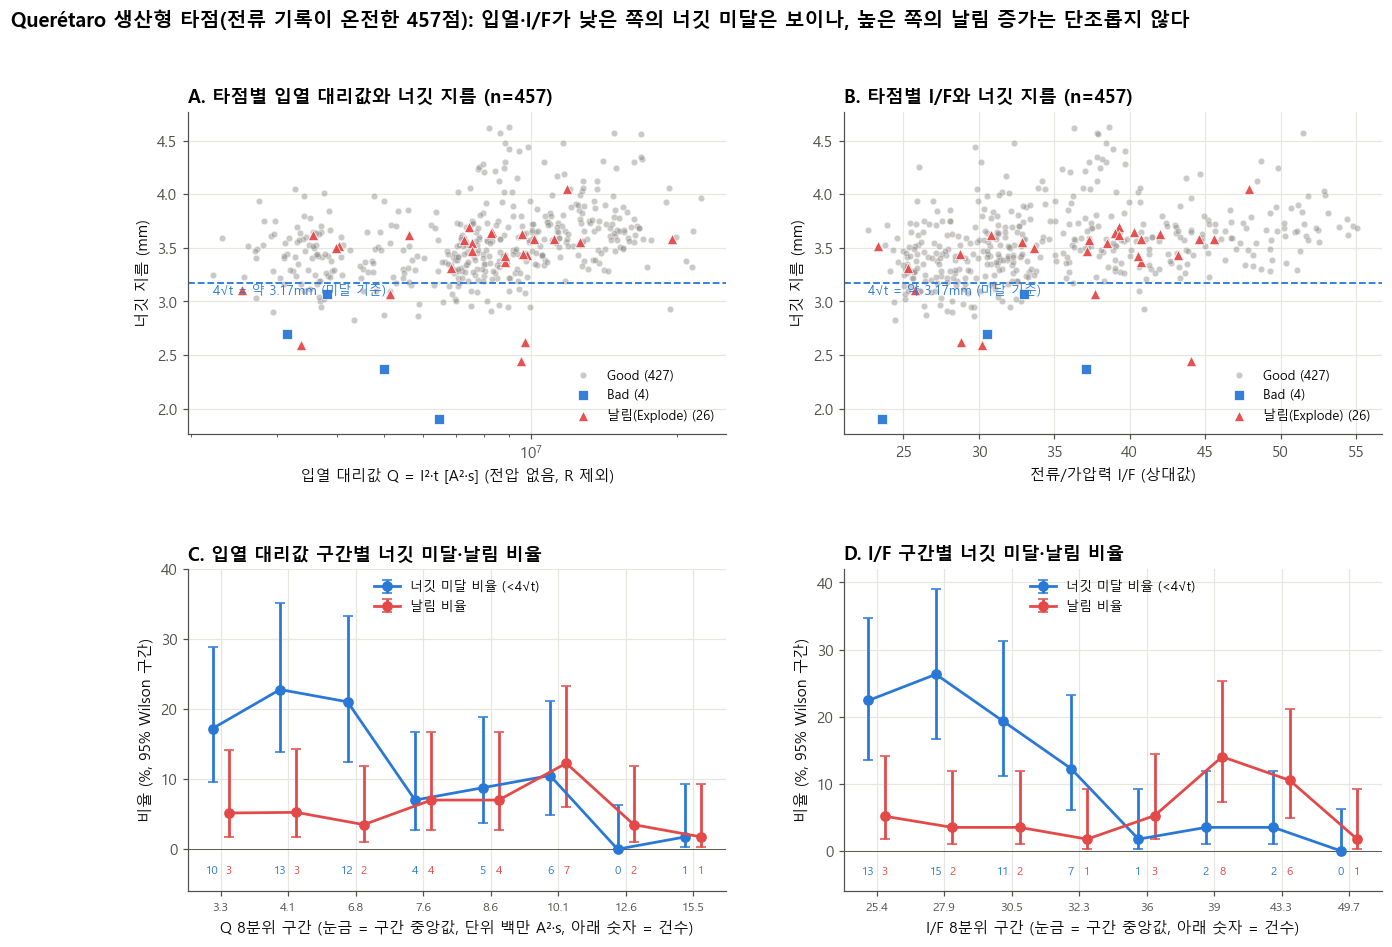

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(14, 9.2), gridspec_kw=dict(hspace=.42, wspace=.22))
for j, (col, B_, xl) in enumerate((("Q", BQ, "입열 대리값 Q = I²·t [A²·s] (전압 없음, R 제외)"), ("IF", BI, "전류/가압력 I/F (상대값)"))):
    ax = axs[0, j]
    for cat, c, m, lab in (("Good", P.GRAY, "o", "Good"), ("Bad", P.PAL[0], "s", "Bad"), ("Explode", P.PAL[7], "^", "날림(Explode)")):
        d_ = Q[Q.cat == cat]
        ax.scatter(d_[col], d_.nug, s=18 if cat == "Good" else 46, c=c, marker=m, alpha=.45 if cat == "Good" else .95, edgecolor="white", lw=.5, label=f"{lab} ({len(d_)})", zorder=3 if cat != "Good" else 2)
    ax.axhline(Q.nug_min.mean(), color=P.PAL[0], ls="--", lw=1.2); ax.text(Q[col].min(), Q.nug_min.mean() - .12, f"4√t = 약 {Q.nug_min.mean():.2f}mm (미달 기준)", color=P.PAL[0], fontsize=8.5)
    if col == "Q": ax.set_xscale("log")
    ax.set_xlabel(xl); ax.set_ylabel("너깃 지름 (mm)"); ax.legend(fontsize=8.5, loc="lower right")
    ax.set_title(f"{'A' if j == 0 else 'B'}. 타점별 {'입열 대리값' if j == 0 else 'I/F'}와 너깃 지름 (n={len(Q)})", loc="left", fontweight="bold")
    ax = axs[1, j]; x = np.arange(len(B_))
    for out, c, lab, off in (("undersize", P.PAL[0], "너깃 미달 비율 (<4√t)", -.12), ("expl", P.PAL[7], "날림 비율", .12)):
        ax.errorbar(x + off, B_[out] * 100, yerr=[(B_[out] - B_[out + "_lo"]) * 100, (B_[out + "_hi"] - B_[out]) * 100], fmt="o-", color=c, capsize=3, lw=1.8, label=lab)
        for xi, (k, n_) in enumerate(zip(B_[out + "_k"], B_.n)):
            ax.text(xi + off, -3.5, f"{k}", color=c, ha="center", fontsize=7.5)
    ax.set_xticks(x); ax.set_xticklabels([f"{v:.3g}" if col == "IF" else f"{v/1e6:.1f}" for v in B_.x중앙값], fontsize=8)
    ax.set_ylim(-6, max(40, (B_[["undersize_hi", "expl_hi"]].max().max()) * 100 + 3)); ax.axhline(0, color=P.INK2, lw=.6)
    ax.set_xlabel(f"{'Q' if col == 'Q' else 'I/F'} 8분위 구간 (눈금 = 구간 중앙값{', 단위 백만 A²·s' if col == 'Q' else ''}, 아래 숫자 = 건수)"); ax.set_ylabel("비율 (%, 95% Wilson 구간)")
    ax.legend(fontsize=8.5, loc="upper center")
    ax.set_title(f"{'C' if j == 0 else 'D'}. {'입열 대리값' if j == 0 else 'I/F'} 구간별 너깃 미달·날림 비율", loc="left", fontweight="bold")
fig.suptitle("Querétaro 생산형 타점(전류 기록이 온전한 457점): 입열·I/F가 낮은 쪽의 너깃 미달은 보이나, 높은 쪽의 날림 증가는 단조롭지 않다", x=.01, ha="left", fontsize=13, fontweight="bold")
P.save(fig, "22_queretaro_boundaries"); plt.show()

### 3-1. 날림이 몰린 조건 칸
날림이 입열(Q)보다 특정 칸에 몰려 있는지 본다.

In [10]:
cz = Q.groupby("cell").agg(n=("nug", "size"), 날림=("expl", "sum"), Q중앙값=("Q", "median"), IF중앙값=("IF", "median"), 전류=("I_body", "mean"), 너깃=("nug", "mean"))
cz["날림률"] = cz.날림 / cz.n
cz = cz.sort_values("Q중앙값"); display(cz.round(3))
print("칸 단위 Spearman: Q중앙값–날림률 ρ=%+.2f, I/F중앙값–날림률 ρ=%+.2f, 전류–날림률 ρ=%+.2f (칸 11개)" % (
    stats.spearmanr(cz.Q중앙값, cz.날림률)[0], stats.spearmanr(cz.IF중앙값, cz.날림률)[0], stats.spearmanr(cz.전류, cz.날림률)[0]))

,n,날림,Q중앙값,IF중앙값,전류,너깃,날림률
cell,,,,,,,
60psi/15°/400ms,49,5,3.556212e+06,31.016,3041.618,3.450,0.102
60psi/0°/400ms,50,1,3.578225e+06,31.917,2906.740,3.360,0.020
80psi/0°/600ms,49,1,5.687046e+06,28.475,3074.248,3.360,0.020
80psi/0°/800ms,51,1,7.217686e+06,25.897,3011.182,3.328,0.020
60psi/15°/600ms,51,9,8.524174e+06,40.058,3746.715,3.494,0.176
60psi/0°/1000ms,21,0,8.649390e+06,37.844,2845.899,4.124,0.000
60psi/15°/800ms,50,5,9.978414e+06,44.062,3482.852,3.630,0.100
80psi/0°/1000ms,29,0,1.003363e+07,30.291,3180.268,3.484,0.000
60psi/15°/1200ms,30,0,1.164713e+07,32.619,3147.319,3.765,0.000


칸 단위 Spearman: Q중앙값–날림률 ρ=-0.28, I/F중앙값–날림률 ρ=+0.07, 전류–날림률 ρ=+0.27 (칸 11개)
